# Model Selection (with Visualizations)

This notebook gives you a hands-on, **simple** tour of model selection using:
- a **polynomial regression** example (degree as complexity),
- a **k-NN classifier** on a 2D dataset (k as complexity).

It connects to the course topics: ERM, overfitting/underfitting, bias–variance, metrics, **cross-validation**, and a taste of **regularization**.

> Run this in **Google Colab** (Runtime → Change runtime type → Python 3).

**This is the _student_ version** — cells marked with `TODO` require your edits.

In [1]:
# Basic setup
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(42)  # reproducibility


## Part 1 — Polynomial Regression: Choosing the Degree

We simulate a nonlinear 1D relationship with noise. We'll:
1. Fit polynomial models of increasing degree `d`.
2. Measure **train**, **validation**, and **cross-validation** errors.
3. Visualize the fit and the **error vs degree** curves to see **overfitting** and **underfitting** in action.


In [7]:
# Generate nonlinear data
n = 120
X = np.linspace(-3, 3, n).reshape(-1, 1)
y_true_fn = lambda x: np.sinc(x) + 0.1*np.cos(3*x)  # smooth target
y = y_true_fn(X).ravel() + 0.25*np.random.randn(n)



# Train/val/test split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=0)

len(X_train), len(X_val), len(X_test)


(72, 24, 24)

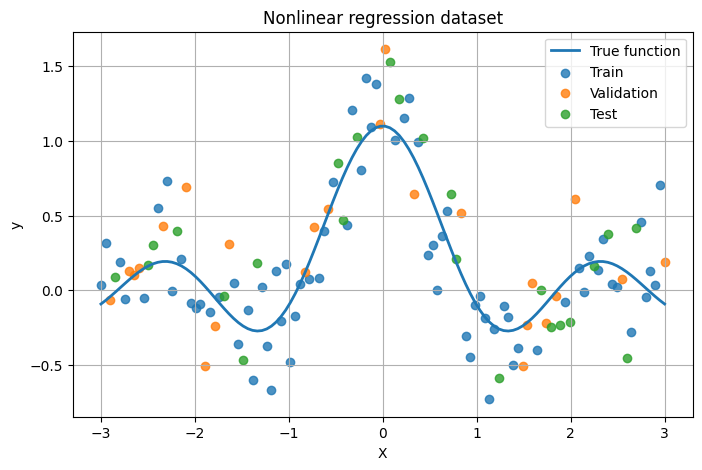

In [13]:
plt.figure(figsize=(8, 5))

# True underlying function
plt.plot(X, y_true_fn(X).ravel(),
         linewidth=2,
         label="True function")

# Train / validation / test observations
plt.scatter(X_train, y_train, label="Train", alpha=0.8)
plt.scatter(X_val, y_val, label="Validation", alpha=0.8)
plt.scatter(X_test, y_test, label="Test", alpha=0.8)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Nonlinear regression dataset")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
# Sweep degrees and compute errors (TRAIN, VAL, and K-fold CV)
degrees = list(range(0, 16))
train_mse, val_mse, cv_mse = [], [], []

kf = KFold(n_splits=5, shuffle=True, random_state=0)

for d in degrees:
    model = Pipeline([
        ("poly", PolynomialFeatures(d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression())
    ])
    # TODO: fit on the training set
    # model.fit( ... )
    model.fit(X_train, y_train)
    #raise NotImplementedError("Fit the model on (X_train, y_train)")

    # TODO: compute predictions and MSE on train and val
    y_pred_tr = model.predict(X_train)
    y_pred_val =  model.predict(X_val)
    train_mse.append(mean_squared_error(y_train,y_pred_tr))
    val_mse.append(mean_squared_error(y_val,y_pred_val))

    # TODO: 5-fold CV MSE (use negative MSE returned by cross_val_score)
    scores = cross_val_score( model, X_train, y_train, scoring="neg_mean_squared_error", cv=kf)
    cv_mse.append(-scores.mean)
    # cv_mse.append( ... )

train_mse, val_mse, cv_mse


ValueError: Setting degree to zero and include_bias to False would result in an empty output array.

**Plot error vs degree** to visualize under/overfitting and the stabilizing effect of cross-validation.


In [ ]:
plt.figure(figsize=(6,4))
plt.plot(degrees, train_mse, marker='o', label='Train MSE')
plt.plot(degrees, val_mse, marker='o', label='Validation MSE')
plt.plot(degrees, cv_mse, marker='o', label='5-fold CV MSE')
plt.xlabel("Polynomial degree")
plt.ylabel("MSE")
plt.title("Error vs Degree")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Visualize fits for a **chosen degree**
d_star = 10  # TODO: try changing this after inspecting the curves
model = Pipeline([
    ("poly", PolynomialFeatures(d_star, include_bias=False)),
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

# TODO: fit on train, evaluate on test, and plot predictions vs ground truth
# model.fit(...)
# test_mse = ...
# print("Test MSE (degree=%d): %.4f" % (d_star, test_mse))

# Plot
xx = np.linspace(X.min(), X.max(), 600).reshape(-1,1)
# y_hat = model.predict(xx)
# plt.figure(figsize=(6,4))
# plt.scatter(X_train, y_train, s=20, alpha=0.6, label="Train")
# plt.scatter(X_val, y_val, s=20, alpha=0.6, label="Val")
# plt.scatter(X_test, y_test, s=20, alpha=0.6, label="Test")
# plt.plot(xx, y_true_fn(xx), lw=2, label="True function")
# plt.plot(xx, y_hat, lw=2, label=f"Poly(d={d_star})")
# plt.legend(); plt.title("Fit visualization"); plt.grid(True); plt.show()


### Optional: Regularization (Ridge) for high-degree polynomials

High degrees can overfit. Let's see how **Ridge** (L2) helps stabilize the fit.


In [ ]:
d_high = 15
alphas = [0.0, 0.01, 0.1, 1.0, 10.0]  # alpha=0 ≈ OLS

# TODO: For each alpha, build a pipeline with PolynomialFeatures(d_high) + StandardScaler + Ridge(alpha)
# Compute test MSE and plot the fitted curves.
raise NotImplementedError("Implement the Ridge sweep over alphas.")


## Part 2 — k-NN Classification: Choosing **k**

We'll generate a 2D **two-moons** dataset and:
1. Use **Stratified K-Fold** cross-validation to evaluate accuracy for different `k`.
2. Pick the best `k`.
3. Visualize the **decision boundary** and the **confusion matrix** on a held-out test set.


In [ ]:
# Two-moons dataset
Xm, ym = make_moons(n_samples=600, noise=0.25, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)
Xm_tr.shape, Xm_te.shape


In [ ]:
# Cross-validate k
k_values = list(range(1, 26, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_acc = []

for k in k_values:
    # TODO: define KNeighborsClassifier with n_neighbors=k
    # model = ...
    # scores = cross_val_score( ... , scoring="accuracy", cv=cv)
    # cv_acc.append(scores.mean())
    raise NotImplementedError("Implement KNN CV sweep.")

# TODO: choose best k based on cv_acc
# best_k = k_values[ ... ]
# best_k


In [ ]:
plt.figure(figsize=(6,4))
plt.plot(k_values, cv_acc, marker='o')
plt.xlabel("k (neighbors)")
plt.ylabel("CV Accuracy")
plt.title("k-NN: Cross-validated accuracy vs k")
plt.grid(True); plt.show()


In [ ]:
# Train with best_k and visualize decision boundary + confusion matrix
# TODO: fit KNN(best_k) on Xm_tr and evaluate on Xm_te
# model = ...
# model.fit(...)
# y_pred = ...
# acc = ...
# print(f"Test accuracy: {acc:.3f}")

# Decision boundary
# xx, yy = np.meshgrid(np.linspace(Xm[:,0].min()-0.5, Xm[:,0].max()+0.5, 300),
#                      np.linspace(Xm[:,1].min()-0.5, Xm[:,1].max()+0.5, 300))
# Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
# plt.figure(figsize=(6,4))
# plt.contourf(xx, yy, Z, alpha=0.2)
# plt.scatter(Xm_te[:,0], Xm_te[:,1], c=ym_te, s=15, edgecolor="k", alpha=0.8)
# plt.title(f"k-NN decision boundary (k={best_k})")
# plt.show()

# Confusion matrix
# cm = confusion_matrix(ym_te, y_pred)
# ConfusionMatrixDisplay(cm).plot()
# plt.title("Confusion Matrix (Test)")
# plt.show()


## Takeaways

- **Model selection** is about choosing complexity (degree `d`, neighbors `k`, regularization `alpha`) that **generalizes** best.
- Use **proper splits** and prefer **k-fold cross-validation** for robust estimates.
- Watch the **bias–variance** trade-off: too simple → underfit, too complex → overfit.
- Regularization (e.g., **Ridge**) helps tame complexity when features are rich (e.g., high-degree polynomials).
